# 08 — Final Cross-Model Comparison

This notebook performs the final comparison of the project's five primary
classification models using a common finalized modeling configuration.

All primary models use:

- the same 15 pre-contact predictors
- `duration` excluded to prevent post-contact information leakage
- the same 70/15/15 stratified train/validation/test split
- the same held-out test observations
- the same evaluation metrics

The primary comparison includes Logistic Regression, K-Nearest Neighbors,
Linear Discriminant Analysis, Quadratic Discriminant Analysis, and Gaussian
Naive Bayes, with a majority-class baseline for reference.

Random Forest is evaluated separately as a supplementary course-driven
ensemble model.

In [63]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import RocCurveDisplay

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import (
    evaluate_binary_classifier,
    results_to_dataframe,
    get_confusion_matrix,
    cross_validate_classifier,
    cross_validation_results_to_dataframe,
    bootstrap_classification_metrics,
    bootstrap_results_to_dataframe,
)

from src.preprocessing import build_preprocessor
from src.models import (
    get_student3_models,
    get_supplementary_models,
)

from src.logistic_regression import build_logistic_pipeline
from src.knn import build_knn_pipeline

## Common Modeling Dataset

In [64]:
DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}."
    )

df = pd.read_csv(
    DATA_PATH,
    sep=";",
)

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [65]:
numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
]

model_features = (
    numeric_features
    + categorical_features
)

X_model = df[model_features]

print("Number of predictors:", len(model_features))
print(model_features)

Number of predictors: 15
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [66]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_model,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42,
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("Training positive rate:", y_train.mean())
print("Validation positive rate:", y_val.mean())
print("Testing positive rate:", y_test.mean())

Training: (31647, 15)
Validation: (6782, 15)
Testing: (6782, 15)
Training positive rate: 0.11697791259835055
Validation positive rate: 0.11692716012975524
Testing positive rate: 0.11707460925980537


In [67]:
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

In [68]:
logistic_model = build_logistic_pipeline(
    numeric_features,
    categorical_features,
    random_state=42,
)

logistic_model.set_params(
    classifier__C=100,
    classifier__class_weight="balanced",
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

### Baseline KNN

In [69]:
knn_model = build_knn_pipeline(
    numeric_features,
    categorical_features,
)

### Linear Discriminant Analysis

In [70]:
lda_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
)

lda_model = Pipeline(
    steps=[
        (
            "preprocessor",
            lda_preprocessor,
        ),
        (
            "classifier",
            LinearDiscriminantAnalysis(),
        ),
    ]
)

### Quadratic Discriminant Analysis

In [71]:
student3_models = get_student3_models()

qda_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
    drop_first=True,
)

qda_model = Pipeline(
    steps=[
        (
            "preprocessor",
            qda_preprocessor,
        ),
        (
            "classifier",
            student3_models[
                "Quadratic Discriminant Analysis"
            ],
        ),
    ]
)

### Gaussian Naive Bayes

In [72]:
gnb_preprocessor = build_preprocessor(
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    dense_output=True,
)

gnb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            gnb_preprocessor,
        ),
        (
            "classifier",
            GaussianNB(),
        ),
    ]
)

In [73]:
primary_models = {
    "Majority Class Baseline": baseline_model,
    "Tuned Logistic Regression": logistic_model,
    "Baseline KNN": knn_model,
    "Linear Discriminant Analysis": lda_model,
    "Quadratic Discriminant Analysis": qda_model,
    "Gaussian Naive Bayes": gnb_model,
}

## Fit Primary Models

In [74]:
for model_name, model in primary_models.items():

    model.fit(
        X_train,
        y_train,
    )

    print(
        f"{model_name} fitted."
    )

Majority Class Baseline fitted.
Tuned Logistic Regression fitted.
Baseline KNN fitted.
Linear Discriminant Analysis fitted.
Quadratic Discriminant Analysis fitted.
Gaussian Naive Bayes fitted.


In [75]:
test_predictions = {}
test_probabilities = {}
test_results = []

for model_name, model in primary_models.items():

    predictions = model.predict(
        X_test
    )

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities

    result = evaluate_binary_classifier(
        model_name=model_name,
        y_true=y_test,
        y_pred=predictions,
        y_score=probabilities,
    )

    test_results.append(result)

In [76]:
final_test_df = results_to_dataframe(
    test_results
)

final_test_df = (
    final_test_df
    .sort_values(
        by="f1",
        ascending=False,
    )
    .reset_index(drop=True)
)

final_test_df.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Gaussian Naive Bayes,0.8421,0.3625,0.4597,0.4053,0.7472
1,Linear Discriminant Analysis,0.8946,0.5980,0.3035,0.4027,0.7661
2,Quadratic Discriminant Analysis,0.8826,0.4980,0.3136,0.3849,0.7647
3,Tuned Logistic Regression,0.7566,0.2688,0.6272,0.3763,0.7719
4,Baseline KNN,0.8884,0.5649,0.2028,0.2984,0.7003
5,Majority Class Baseline,0.8829,0.0000,0.0000,0.0000,0.5000


In [77]:
confusion_results = []

for model_name in primary_models:

    cm = get_confusion_matrix(
        y_test,
        test_predictions[model_name],
    )

    tn, fp, fn, tp = cm.ravel()

    confusion_results.append({
        "model": model_name,
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    })

confusion_df = pd.DataFrame(
    confusion_results
)

confusion_df

,model,true_negatives,false_positives,false_negatives,true_positives
0,Majority Class Baseline,5988,0,794,0
1,Tuned Logistic Regression,4633,1355,296,498
2,Baseline KNN,5864,124,633,161
3,Linear Discriminant Analysis,5826,162,553,241
4,Quadratic Discriminant Analysis,5737,251,545,249
5,Gaussian Naive Bayes,5346,642,429,365


### Confusion-Matrix Interpretation

The confusion-matrix results highlight the different ways the models respond to the class imbalance.

Tuned Logistic Regression identifies the largest number of actual subscribers, with 498 true positives and only 296 false negatives. However, this high recall comes at the cost of 1,355 false positives, substantially more than any other primary model.

KNN shows the opposite behavior. It produces only 124 false positives but misses 633 of the 794 actual subscribers, resulting in the lowest recall among the non-baseline classifiers.

LDA is also relatively conservative, producing only 162 false positives and achieving the highest precision among the primary models. However, it misses 553 subscribers. QDA behaves similarly, with 251 false positives and 545 false negatives.

Gaussian Naive Bayes provides a more balanced tradeoff. It identifies 365 actual subscribers while missing 429 and produces 642 false positives. Although it generates more false positives than LDA, QDA, or KNN, its stronger minority-class detection contributes to the highest F1-score among the five primary classifiers.

The majority-class baseline demonstrates why accuracy alone is misleading for this dataset: despite achieving approximately 88.3% accuracy, it predicts no subscribers correctly and misses all 794 positive cases.

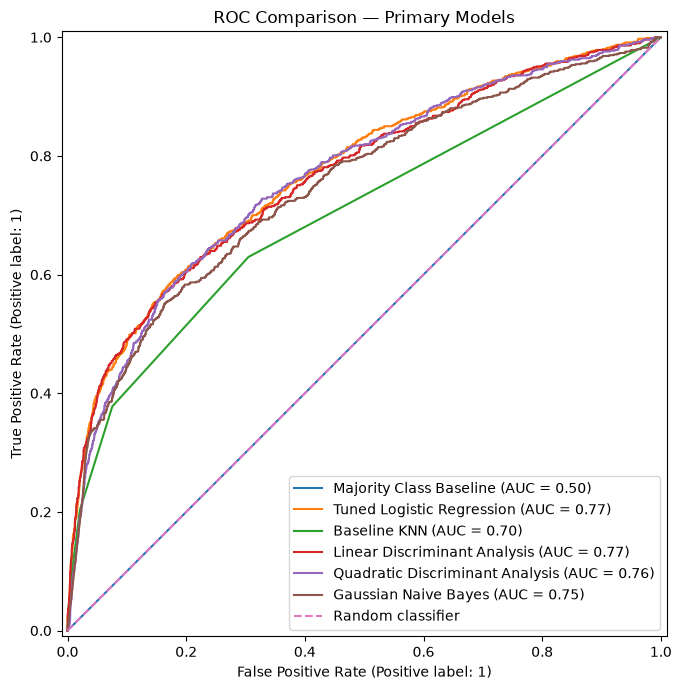

In [78]:
fig, ax = plt.subplots(
    figsize=(9, 7)
)

for model_name in primary_models:

    RocCurveDisplay.from_predictions(
        y_test,
        test_probabilities[model_name],
        name=model_name,
        ax=ax,
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier",
)

ax.set_title(
    "ROC Comparison — Primary Models"
)

ax.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()

In [79]:
primary_cv_results = []

for model_name, model in primary_models.items():

    result = cross_validate_classifier(
        model_name=model_name,
        estimator=model,
        X=X_train,
        y=y_train,
        cv=5,
    )

    primary_cv_results.append(
        result
    )

    print(
        f"{model_name} CV complete."
    )

Majority Class Baseline CV complete.
Tuned Logistic Regression CV complete.
Baseline KNN CV complete.
Linear Discriminant Analysis CV complete.
Quadratic Discriminant Analysis CV complete.
Gaussian Naive Bayes CV complete.


In [80]:
final_cv_df = (
    cross_validation_results_to_dataframe(
        primary_cv_results
    )
)

final_cv_df = (
    final_cv_df
    .sort_values(
        by="f1_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)

final_cv_df.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Gaussian Naive Bayes,0.8393,0.0038,0.3525,0.0102,0.4462,0.0214,0.3937,0.0128,0.7405,0.0123
1,Tuned Logistic Regression,0.7561,0.0052,0.2673,0.0071,0.6229,0.0240,0.3740,0.0105,0.7645,0.0147
2,Quadratic Discriminant Analysis,0.8768,0.0047,0.4592,0.0315,0.2979,0.0221,0.3613,0.0256,0.7562,0.0136
3,Linear Discriminant Analysis,0.8877,0.0022,0.5400,0.0192,0.2701,0.0182,0.3599,0.0197,0.7593,0.0154
4,Baseline KNN,0.8841,0.0017,0.5115,0.0193,0.1969,0.0179,0.2841,0.0210,0.6882,0.0099
5,Majority Class Baseline,0.8830,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000


In [81]:
primary_bootstrap_results = []

for model_name in primary_models:

    result = bootstrap_classification_metrics(
        model_name=model_name,
        y_true=y_test,
        y_pred=test_predictions[
            model_name
        ],
        y_score=test_probabilities[
            model_name
        ],
        n_bootstrap=1000,
        confidence_level=0.95,
        random_state=42,
    )

    primary_bootstrap_results.append(
        result
    )

In [82]:
primary_bootstrap_df = (
    bootstrap_results_to_dataframe(
        primary_bootstrap_results
    )
)

primary_bootstrap_df

,model,n_bootstrap,confidence_level,accuracy,accuracy_ci_lower,accuracy_ci_upper,precision,precision_ci_lower,precision_ci_upper,recall,recall_ci_lower,recall_ci_upper,f1,f1_ci_lower,f1_ci_upper,roc_auc,roc_auc_ci_lower,roc_auc_ci_upper
0,Majority Class Baseline,1000,0.95,0.882925,0.875254,0.890302,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.500000,0.500000
1,Tuned Logistic Regression,1000,0.95,0.756561,0.746535,0.766588,0.268753,0.247854,0.289350,0.627204,0.593588,0.659976,0.376275,0.351842,0.400450,0.771901,0.752410,0.790600
2,Baseline KNN,1000,0.95,0.888381,0.880566,0.895610,0.564912,0.511274,0.618080,0.202771,0.175639,0.230149,0.298424,0.263056,0.333341,0.700315,0.680106,0.721471
3,Linear Discriminant Analysis,1000,0.95,0.894574,0.886903,0.902094,0.598015,0.548126,0.642683,0.303526,0.271288,0.333773,0.402673,0.365979,0.436693,0.766066,0.746261,0.785718
4,Quadratic Discriminant Analysis,1000,0.95,0.882630,0.874665,0.890593,0.498000,0.453271,0.537116,0.313602,0.280094,0.346251,0.384853,0.347754,0.417171,0.764661,0.745564,0.784017
5,Gaussian Naive Bayes,1000,0.95,0.842082,0.833235,0.851224,0.362463,0.331692,0.393113,0.459698,0.423696,0.492754,0.405330,0.374371,0.433722,0.747203,0.727895,0.766851


In [83]:
bootstrap_summary_df = pd.DataFrame({
    "Model":
        primary_bootstrap_df["model"],

    "Precision":
        primary_bootstrap_df.apply(
            lambda row:
            f'{row["precision"]:.3f} '
            f'[{row["precision_ci_lower"]:.3f}, '
            f'{row["precision_ci_upper"]:.3f}]',
            axis=1,
        ),

    "Recall":
        primary_bootstrap_df.apply(
            lambda row:
            f'{row["recall"]:.3f} '
            f'[{row["recall_ci_lower"]:.3f}, '
            f'{row["recall_ci_upper"]:.3f}]',
            axis=1,
        ),

    "F1":
        primary_bootstrap_df.apply(
            lambda row:
            f'{row["f1"]:.3f} '
            f'[{row["f1_ci_lower"]:.3f}, '
            f'{row["f1_ci_upper"]:.3f}]',
            axis=1,
        ),

    "ROC-AUC":
        primary_bootstrap_df.apply(
            lambda row:
            f'{row["roc_auc"]:.3f} '
            f'[{row["roc_auc_ci_lower"]:.3f}, '
            f'{row["roc_auc_ci_upper"]:.3f}]',
            axis=1,
        ),
})

bootstrap_summary_df

,Model,Precision,Recall,F1,ROC-AUC
0,Majority Class Baseline,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]"
1,Tuned Logistic Regression,"0.269 [0.248, 0.289]","0.627 [0.594, 0.660]","0.376 [0.352, 0.400]","0.772 [0.752, 0.791]"
2,Baseline KNN,"0.565 [0.511, 0.618]","0.203 [0.176, 0.230]","0.298 [0.263, 0.333]","0.700 [0.680, 0.721]"
3,Linear Discriminant Analysis,"0.598 [0.548, 0.643]","0.304 [0.271, 0.334]","0.403 [0.366, 0.437]","0.766 [0.746, 0.786]"
4,Quadratic Discriminant Analysis,"0.498 [0.453, 0.537]","0.314 [0.280, 0.346]","0.385 [0.348, 0.417]","0.765 [0.746, 0.784]"
5,Gaussian Naive Bayes,"0.362 [0.332, 0.393]","0.460 [0.424, 0.493]","0.405 [0.374, 0.434]","0.747 [0.728, 0.767]"


## Supplementary Random Forest Comparison

Random Forest was evaluated as a supplementary ensemble-learning model
beyond the five primary candidate classifiers.

It uses the same finalized 15-feature pre-contact dataset and the same
train/validation/test split, allowing its performance to be compared
directly with the primary classifiers.

In [84]:
rf_numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
            ),
        ),
    ]
)

rf_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent",
            ),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
            ),
        ),
    ]
)

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            rf_numeric_pipeline,
            numeric_features,
        ),
        (
            "categorical",
            rf_categorical_pipeline,
            categorical_features,
        ),
    ]
)

In [85]:
rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_preprocessor,
        ),
        (
            "classifier",
            get_supplementary_models()[
                "Random Forest"
            ],
        ),
    ]
)

rf_model.fit(
    X_train,
    y_train,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','balance','day',...,'contact','month','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

In [86]:
rf_predictions = rf_model.predict(
    X_test
)

rf_probabilities = (
    rf_model.predict_proba(
        X_test
    )[:, 1]
)

rf_result = evaluate_binary_classifier(
    model_name="Random Forest (Supplementary)",
    y_true=y_test,
    y_pred=rf_predictions,
    y_score=rf_probabilities,
)

rf_result

{'model': 'Random Forest (Supplementary)',
 'accuracy': 0.8833677381303451,
 'precision': 0.50231124807396,
 'recall': 0.4105793450881612,
 'f1': 0.4518364518364518,
 'roc_auc': 0.7948692304844786}

In [87]:
rf_bootstrap_result = bootstrap_classification_metrics(
    model_name="Random Forest (Supplementary)",
    y_true=y_test,
    y_pred=rf_predictions,
    y_score=rf_probabilities,
    n_bootstrap=1000,
    confidence_level=0.95,
    random_state=42,
)

rf_bootstrap_result

{'model': 'Random Forest (Supplementary)',
 'n_bootstrap': 1000,
 'confidence_level': 0.95,
 'accuracy': 0.8833677381303451,
 'accuracy_ci_lower': np.float64(0.875696697139487),
 'accuracy_ci_upper': np.float64(0.8911825420230021),
 'precision': 0.50231124807396,
 'precision_ci_lower': np.float64(0.4653571564739973),
 'precision_ci_upper': np.float64(0.5396619826862468),
 'recall': 0.4105793450881612,
 'recall_ci_lower': np.float64(0.3785140062066471),
 'recall_ci_upper': np.float64(0.44340909489102254),
 'f1': 0.4518364518364518,
 'f1_ci_lower': np.float64(0.4203350005270987),
 'f1_ci_upper': np.float64(0.48248898716841565),
 'roc_auc': 0.7948692304844786,
 'roc_auc_ci_lower': np.float64(0.775902648611318),
 'roc_auc_ci_upper': np.float64(0.8126239408354954)}

In [88]:
overall_results_df = results_to_dataframe(
    test_results + [rf_result]
)

overall_results_df = (
    overall_results_df
    .sort_values(
        by="f1",
        ascending=False,
    )
    .reset_index(drop=True)
)

overall_results_df.round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Random Forest (Supplementary),0.8834,0.5023,0.4106,0.4518,0.7949
1,Gaussian Naive Bayes,0.8421,0.3625,0.4597,0.4053,0.7472
2,Linear Discriminant Analysis,0.8946,0.5980,0.3035,0.4027,0.7661
3,Quadratic Discriminant Analysis,0.8826,0.4980,0.3136,0.3849,0.7647
4,Tuned Logistic Regression,0.7566,0.2688,0.6272,0.3763,0.7719
5,Baseline KNN,0.8884,0.5649,0.2028,0.2984,0.7003
6,Majority Class Baseline,0.8829,0.0000,0.0000,0.0000,0.5000


In [89]:
overall_bootstrap_results = (
    primary_bootstrap_results
    + [rf_bootstrap_result]
)

overall_bootstrap_df = (
    bootstrap_results_to_dataframe(
        overall_bootstrap_results
    )
)

In [90]:
overall_bootstrap_summary_df = pd.DataFrame({
    "Model":
        overall_bootstrap_df["model"],

    "Precision":
        overall_bootstrap_df.apply(
            lambda row:
            f'{row["precision"]:.3f} '
            f'[{row["precision_ci_lower"]:.3f}, '
            f'{row["precision_ci_upper"]:.3f}]',
            axis=1,
        ),

    "Recall":
        overall_bootstrap_df.apply(
            lambda row:
            f'{row["recall"]:.3f} '
            f'[{row["recall_ci_lower"]:.3f}, '
            f'{row["recall_ci_upper"]:.3f}]',
            axis=1,
        ),

    "F1":
        overall_bootstrap_df.apply(
            lambda row:
            f'{row["f1"]:.3f} '
            f'[{row["f1_ci_lower"]:.3f}, '
            f'{row["f1_ci_upper"]:.3f}]',
            axis=1,
        ),

    "ROC-AUC":
        overall_bootstrap_df.apply(
            lambda row:
            f'{row["roc_auc"]:.3f} '
            f'[{row["roc_auc_ci_lower"]:.3f}, '
            f'{row["roc_auc_ci_upper"]:.3f}]',
            axis=1,
        ),
})

overall_bootstrap_summary_df

,Model,Precision,Recall,F1,ROC-AUC
0,Majority Class Baseline,"0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]"
1,Tuned Logistic Regression,"0.269 [0.248, 0.289]","0.627 [0.594, 0.660]","0.376 [0.352, 0.400]","0.772 [0.752, 0.791]"
2,Baseline KNN,"0.565 [0.511, 0.618]","0.203 [0.176, 0.230]","0.298 [0.263, 0.333]","0.700 [0.680, 0.721]"
3,Linear Discriminant Analysis,"0.598 [0.548, 0.643]","0.304 [0.271, 0.334]","0.403 [0.366, 0.437]","0.766 [0.746, 0.786]"
4,Quadratic Discriminant Analysis,"0.498 [0.453, 0.537]","0.314 [0.280, 0.346]","0.385 [0.348, 0.417]","0.765 [0.746, 0.784]"
5,Gaussian Naive Bayes,"0.362 [0.332, 0.393]","0.460 [0.424, 0.493]","0.405 [0.374, 0.434]","0.747 [0.728, 0.767]"
6,Random Forest (Supplementary),"0.502 [0.465, 0.540]","0.411 [0.379, 0.443]","0.452 [0.420, 0.482]","0.795 [0.776, 0.813]"


In [91]:
model_recommendation_df = pd.DataFrame({
    "Use Case": [
        "Best balanced primary model",
        "Highest recall / minimize missed subscribers",
        "Highest precision primary model",
        "Best overall including supplementary model",
    ],
    "Recommended Model": [
        "Gaussian Naive Bayes",
        "Tuned Logistic Regression",
        "Linear Discriminant Analysis",
        "Random Forest",
    ],
    "Reason": [
        "Highest primary-model F1 with relatively strong recall",
        "Highest recall at 0.627",
        "Highest primary-model precision at 0.598",
        "Highest F1 and ROC-AUC with balanced precision and recall",
    ],
})

model_recommendation_df

,Use Case,Recommended Model,Reason
0,Best balanced primary model,Gaussian Naive Bayes,Highest primary-model F1 with relatively stron...
1,Highest recall / minimize missed subscribers,Tuned Logistic Regression,Highest recall at 0.627
2,Highest precision primary model,Linear Discriminant Analysis,Highest primary-model precision at 0.598
3,Best overall including supplementary model,Random Forest,Highest F1 and ROC-AUC with balanced precision...


## Final Model Recommendation

The final comparison demonstrates substantial differences in classification behavior across the candidate models, particularly in how they balance precision and recall for the minority subscriber class.

Among the five primary candidate classifiers, Gaussian Naive Bayes produced the highest held-out F1-score at 0.405, with a 95% bootstrap confidence interval of [0.374, 0.434]. It also achieved a recall of 0.460, allowing it to identify considerably more actual subscribers than LDA, QDA, or KNN. Its cross-validation results were also reasonably consistent with its test performance, supporting Gaussian Naive Bayes as a strong balanced choice among the primary models.

Linear Discriminant Analysis produced a very similar test F1-score of 0.403 [0.366, 0.437] and the highest precision among the primary classifiers at 0.598. Because the F1 confidence intervals for LDA and Gaussian Naive Bayes overlap substantially, their small difference in test F1-score should not be interpreted as evidence that Gaussian Naive Bayes is definitively superior. Instead, the models reflect different classification priorities: LDA favors precision, while Gaussian Naive Bayes identifies a larger proportion of actual subscribers.

Tuned Logistic Regression produced the highest recall of all primary models at 0.627 [0.594, 0.660] and the highest primary-model ROC-AUC at 0.772 [0.752, 0.791]. However, this higher recall came with substantially lower precision of 0.269 [0.248, 0.289]. Logistic Regression would therefore be preferable when the primary objective is to minimize missed potential subscribers and additional false-positive contacts are acceptable.

KNN produced relatively high precision but very low recall, identifying only about 20% of actual subscribers. QDA provided more balanced performance than KNN but did not clearly outperform LDA or Gaussian Naive Bayes.

The supplementary Random Forest model produced the strongest overall point-estimate performance. It achieved an F1-score of 0.452 [0.420, 0.482] and ROC-AUC of 0.795 [0.776, 0.813], both higher than the corresponding point estimates for the five primary classifiers. Random Forest also maintained a relatively balanced precision of 0.502 and recall of 0.411.

Random Forest's F1 confidence interval overlaps with those of Gaussian Naive Bayes and LDA, so the observed advantage should be interpreted cautiously rather than as definitive statistical superiority. Nevertheless, its combination of F1-score, ROC-AUC, precision-recall balance, cross-validation stability, and consistency between validation and test performance makes Random Forest the strongest overall model evaluated in this project.

Therefore, Gaussian Naive Bayes is recommended as the strongest balanced model among the five primary candidate classifiers, while Random Forest is the overall recommended model when the supplementary ensemble-learning experiment is included.